# Задача 9. Markov Chain Monte-Carlo

Реализуем иерархическую модель задач 1--3 в PyMC. Для события
с энергией $E$:

$$N_\gamma\sim\mathrm{Poisson}(EY),\qquad
N_{\rm hit}\mid N_\gamma\sim\mathrm{Binomial}(N_\gamma,p),$$
$$Q\mid N_{\rm hit}\sim\mathrm{Poisson}(aN_{\rm hit}).$$

В центре сферы вероятность попадания равна геометрической доле
покрытия. Для сравнения строим отклик задачи 4, где число
испущенных фотонов фиксировано. Дополнительно учитываем
поглощение с длиной $L=8$ м.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm

from model import Detector, Source, simulate_charge_ensemble

detector = Detector(R=2.0, N=40, r=0.10, a=0.5)
source = Source(Y=10_000.0, position=np.zeros(3))
energy = 1.0
n_events = 10_000
p_hit = detector.geometric_coverage_fraction
p_attenuated = p_hit * np.exp(-detector.R / 8.0)

print(f"Геометрическая вероятность попадания: {p_hit:.6f}")
print(f"Вероятность с L=8 м: {p_attenuated:.6f}")

Геометрическая вероятность попадания: 0.025016
Вероятность с L=8 м: 0.019482


In [2]:
with pm.Model() as detector_model:
    n_gamma = pm.Poisson("n_gamma", mu=energy * source.Y)
    n_hits = pm.Binomial("n_hits", n=n_gamma, p=p_hit)
    total_pe = pm.Poisson("total_pe", mu=detector.a * n_hits)
    prior = pm.sample_prior_predictive(
        draws=n_events, random_seed=9001
    )

q_pymc = prior.prior["total_pe"].values.reshape(-1)

with pm.Model() as attenuated_model:
    n_gamma_att = pm.Poisson("n_gamma", mu=energy * source.Y)
    n_hits_att = pm.Binomial(
        "n_hits", n=n_gamma_att, p=p_attenuated
    )
    total_pe_att = pm.Poisson(
        "total_pe", mu=detector.a * n_hits_att
    )
    prior_att = pm.sample_prior_predictive(
        draws=n_events, random_seed=9002
    )

q_attenuated = prior_att.prior["total_pe"].values.reshape(-1)

Sampling: [n_gamma, n_hits, total_pe]


Sampling: [n_gamma, n_hits, total_pe]


                 среднее      стандартное отклонение
PyMC:             124.974          13.610
Задача 4:         125.188          13.633
PyMC, L=8 м:       97.365          12.043


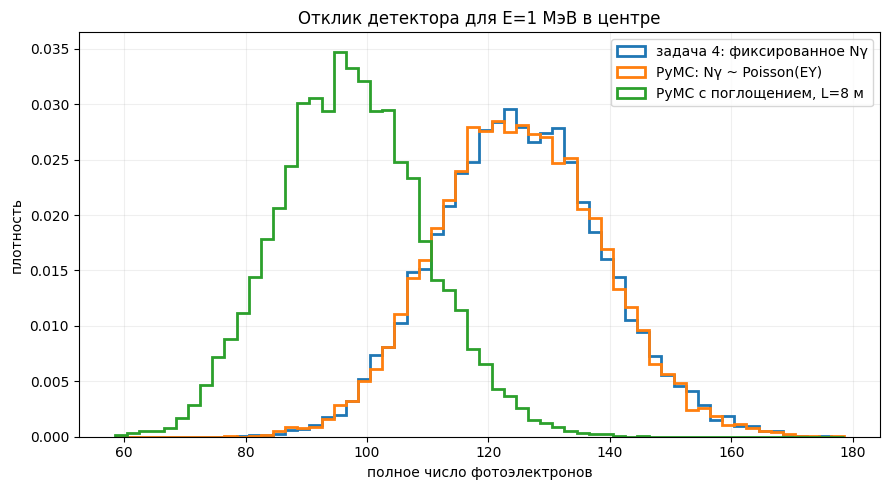

In [3]:
_, q_task4 = simulate_charge_ensemble(
    detector, source, energy, n_events, p_hit,
    np.random.default_rng(9003),
)

print("                 среднее      стандартное отклонение")
print(f"PyMC:            {q_pymc.mean():8.3f}        {q_pymc.std(ddof=1):8.3f}")
print(f"Задача 4:        {q_task4.mean():8.3f}        {q_task4.std(ddof=1):8.3f}")
print(f"PyMC, L=8 м:     {q_attenuated.mean():8.3f}        {q_attenuated.std(ddof=1):8.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
low = min(q_pymc.min(), q_task4.min(), q_attenuated.min())
high = max(q_pymc.max(), q_task4.max(), q_attenuated.max())
bins = np.arange(low - 0.5, high + 1.5, 2)
ax.hist(q_task4, bins=bins, density=True, histtype="step",
        linewidth=2, label="задача 4: фиксированное Nγ")
ax.hist(q_pymc, bins=bins, density=True, histtype="step",
        linewidth=2, label="PyMC: Nγ ~ Poisson(EY)")
ax.hist(q_attenuated, bins=bins, density=True, histtype="step",
        linewidth=2, label="PyMC с поглощением, L=8 м")
ax.set(xlabel="полное число фотоэлектронов", ylabel="плотность",
       title="Отклик детектора для E=1 МэВ в центре")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
fig.savefig("figures/task9_pymc_response.png", dpi=180,
            bbox_inches="tight")
plt.show()

**Вывод.** Оба расчёта дают одинаковое среднее. Распределение
PyMC немного шире результата задачи 4 из-за дополнительных
пуассоновских флуктуаций числа испущенных фотонов. Поглощение
уменьшает средний заряд примерно в $\exp(-R/L)$ раз.